# Eksperimen MovieLens-1M: Cold-to-Warm Threshold
Replikasi dari *Recommendation Is a Dish Better Served Warm* (Gusak dkk., RecSys 2025) untuk dataset ML-1M.

| | Paper | Notebook ini |
|---|---|---|
| Dataset | ML-1M, BeerAdvocate, Behance, Amazon Beauty | ML-1M |
| Model | EASE^R, PureSVD, ItemKNN, SASRec-CE | ItemKNN, EASE^R (User-Based); ItemKNN tanpa pruning (Item-Based) |
| User-Based | semua user test | sama; sampling diulang 5× per user; film di riwayat **lengkap** dibuang dari kandidat |
| Item-Based | S = 1000 item, successive evaluation penuh | sama (S = 1000, semua user test, semua langkah) |
| Tuning | 20 titik acak dari grid | grid kecil penuh |
| Lebar sliding window | tidak disebutkan | 3 titik (**asumsi**) |

Data: unduh `ml-1m.zip` dari https://grouplens.org/datasets/movielens/1m/ lalu ekstrak ke `data/raw/ml-1m/`.

In [1]:
import sys, time; sys.path.insert(0, "../src")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import coldwarm as cw
pd.set_option("display.precision", 5)
RUN_ITEM_BASED = True     # ±35 menit; set False kalau hanya butuh User-Based
ITEM_S = 1000             # jumlah item sampel, sama dengan paper
N_REPEATS = 5             # pengulangan sampling riwayat per user (User-Based)
# Item-Based: grid N paper (sampai 64) diperluas sampai 512 untuk mencari titik warm ItemKNN kita
IB_NS = cw.DEFAULT_NS + [96, 128, 192, 256, 384, 512]

## 1. Input & statistik (bandingkan dengan Table 1 paper)

In [2]:
df = cw.load_ml1m("../data/raw/ml-1m/ratings.dat")
df, n_users, n_items = cw.encode(df)
stats = dict(users=n_users, items=n_items, interactions=len(df),
             density=f"{len(df)/(n_users*n_items):.2%}",
             avg_user=round(len(df)/n_users), avg_item=round(len(df)/n_items))
print(stats)
print("Paper: 6,040 user, 3,706 item, 1,000,209 interaksi, density 4.47%, avg user 166, avg item 270")

{'users': 6040, 'items': 3706, 'interactions': 1000209, 'density': '4.47%', 'avg_user': 166, 'avg_item': 270}
Paper: 6,040 user, 3,706 item, 1,000,209 interaksi, density 4.47%, avg user 166, avg item 270


## 2. Preprocessing: split global timepoint (kuantil 0.9)

In [3]:
split = cw.global_timepoint_split(df, q=0.9, val_frac=0.1, include_test_history_in_train=True, seed=0)
print("GT timestamp:", pd.to_datetime(split.gt_time, unit="s"))
print("interaksi train:", len(split.train), "| user valid:", len(split.val_hist), "| user test:", len(split.test_hist))
X = cw.to_matrix(split.train, n_users, n_items)

GT timestamp: 2000-12-29 23:42:56.399999976
interaksi train: 836101 | user valid: 483 | user test: 1180


## 3. Tuning hyperparameter di set validasi (NDCG@10)

In [4]:
t = time.time()
knn_grid = [dict(k=k, shrink=s) for k in (10, 25, 50, 100, 200, 400, 800, None) for s in (0, 10, 50)]
knn_params, knn_res = cw.tune(cw.ItemKNN, knn_grid, X, split, n_items)
ease_params, ease_res = cw.tune(cw.EASE, [dict(lam=l) for l in (50, 100, 200, 500, 1000, 2000, 5000)], X, split, n_items)
print("ItemKNN terbaik:", knn_params, "| EASE terbaik:", ease_params, f"| {time.time()-t:.0f}s")
pd.DataFrame([{**p, "NDCG@10": v} for p, v in knn_res]).sort_values("NDCG@10", ascending=False).head()

ItemKNN terbaik: {'k': 400, 'shrink': 50} | EASE terbaik: {'lam': 200} | 67s


,k,shrink,NDCG@10
17,400.0,50,0.04526
15,400.0,0,0.04276
20,800.0,50,0.04270
21,NaN,0,0.04188
23,NaN,50,0.04181


## 4. Contoh output rekomendasi
Contoh rekomendasi top-10 untuk satu user test, memakai riwayat lengkap sebelum GT.

In [5]:
movies = pd.read_csv("../data/raw/ml-1m/movies.dat", sep="::", engine="python",
                     names=["item_id","title","genres"], encoding="latin-1").set_index("item_id")
item_ids = pd.factorize(cw.load_ml1m("../data/raw/ml-1m/ratings.dat")["item_id"])[1]
title = lambda i: movies.loc[item_ids[i], "title"]
knn = cw.ItemKNN(**knn_params).fit(X)
u = next(iter(split.test_hist))
print("5 tontonan terakhir:", [title(i) for i in split.test_hist[u][-5:]])
print("Ground truth (interaksi pertama setelah GT):", title(split.test_holdout[u][0]))
for r, i in enumerate(cw.recommend(knn, [split.test_hist[u]], n_items, 10)[0], 1):
    print(f"{r:2d}. {title(i)}")

5 tontonan terakhir: ["Wayne's World 2 (1993)", 'Everyone Says I Love You (1996)', "You've Got Mail (1998)", 'Brady Bunch Movie, The (1995)', 'Austin Powers: The Spy Who Shagged Me (1999)']
Ground truth (interaksi pertama setelah GT): Englishman Who Went Up a Hill, But Came Down a Mountain, The (1995)
 1. Groundhog Day (1993)
 2. Forrest Gump (1994)
 3. Star Wars: Episode V - The Empire Strikes Back (1980)
 4. Lethal Weapon (1987)
 5. E.T. the Extra-Terrestrial (1982)
 6. Monty Python and the Holy Grail (1974)
 7. Raiders of the Lost Ark (1981)
 8. Toy Story (1995)
 9. Clueless (1995)
10. Crocodile Dundee (1986)


## 5. User-Based (Sec 3.2)
Model tetap. Riwayat user test di-sample N interaksi (uniform, urutan waktu tetap) sebanyak 5 kali, lalu HR@10 dan NDCG@10 dihitung terhadap interaksi pertama setelah GT. Hasilnya dirata-rata atas user dengan ≥ N interaksi.

**Filter seen:** film yang ada di riwayat **lengkap** user dibuang dari kandidat, bukan hanya N film sampel. Paper tidak merinci hal ini. Tanpa filter ini, slot top-10 terisi film yang sudah pernah ditonton dan HR jatuh ke ±0.025, jauh di bawah Figure 4 paper (±0.05–0.06).

In [6]:
ease = cw.EASE(**ease_params).fit(X)
curves = {name: cw.user_based_curve(m, split, n_items, seed=0, n_repeats=N_REPEATS, filter_full_history=True)
          for name, m in (("ItemKNN", knn), ("EASE^R", ease))}
pd.concat(curves, names=["model"]).droplevel(1).set_index("N", append=True)[["n_users","HR","HR_ci","NDCG","NDCG_ci"]]

n_users       HR    HR_ci     NDCG  NDCG_ci
model   N                                              
ItemKNN 1      1180  0.03203  0.00535  0.01651  0.00313
        2      1180  0.03983  0.00641  0.01960  0.00351
        3      1178  0.04041  0.00685  0.01960  0.00383
        4      1176  0.04898  0.00757  0.02442  0.00413
        5      1175  0.04562  0.00804  0.02270  0.00441
        6      1158  0.04801  0.00812  0.02380  0.00465
        7      1147  0.04743  0.00785  0.02369  0.00440
        8      1134  0.04991  0.00866  0.02455  0.00498
        10     1120  0.05143  0.00905  0.02477  0.00483
        12     1108  0.05487  0.00954  0.02683  0.00529
        16     1093  0.05855  0.01057  0.02818  0.00558
        20     1081  0.05717  0.01106  0.02815  0.00614
        24     1063  0.05287  0.01089  0.02640  0.00609
        32     1028  0.05661  0.01180  0.02853  0.00677
        48      952  0.05798  0.01275  0.02872  0.00721
        64      881  0.05585  0.01332  0.02866  0.00782
EASE^R  1      1180  0.02949  0.00491  0.01479  0.00282
        2      1180  0.03390  0.00521  0.01679  0.00282
        3      1178  0.03769  0.00596  0.01816  0.00319
        4      1176  0.04286  0.00619  0.02010  0.00326
        5      1175  0.04426  0.00702  0.02297  0.00400
        6      1158  0.04508  0.00741  0.02259  0.00407
        7      1147  0.04481  0.00676  0.02241  0.00369
        8      1134  0.04815  0.00738  0.02320  0.00400
        10     1120  0.04839  0.00767  0.02436  0.00410
        12     1108  0.04404  0.00712  0.02205  0.00412
        16     1093  0.05069  0.00819  0.02448  0.00436
        20     1081  0.05883  0.00953  0.02990  0.00558
        24     1063  0.05362  0.00886  0.02825  0.00556
        32     1028  0.05000  0.00919  0.02535  0.00540
        48      952  0.05462  0.01008  0.02726  0.00555
        64      881  0.05426  0.01065  0.02759  0.00620

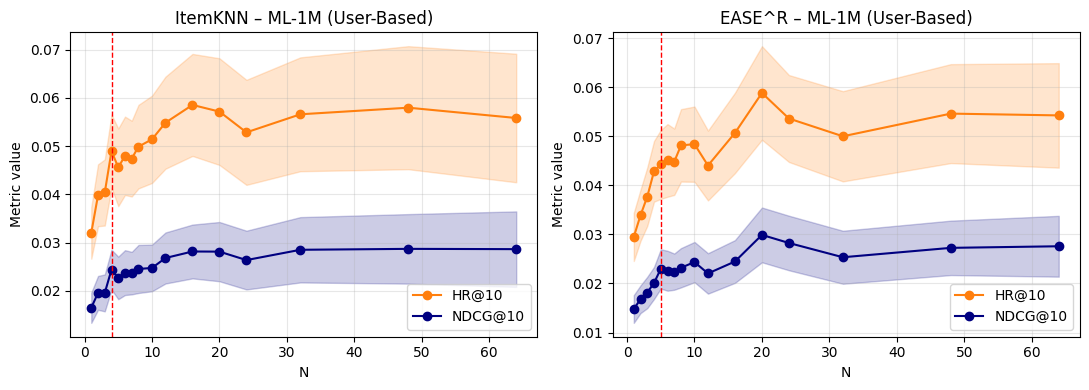

{'ItemKNN': {'HR': 4, 'NDCG': 4}, 'EASE^R': {'HR': 4, 'NDCG': 5}}

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
thr_user = {}
for ax, (name, c) in zip(axes, curves.items()):
    for m, col in (("HR", "tab:orange"), ("NDCG", "navy")):
        ax.plot(c.N, c[m], "o-", color=col, label=f"{m}@10")
        ax.fill_between(c.N, c[m]-c[m+"_ci"], c[m]+c[m+"_ci"], color=col, alpha=.2)
    thr_user[name] = {m: cw.detect_threshold(c.N, c[m])[0] for m in ("HR", "NDCG")}
    if thr_user[name]["NDCG"]: ax.axvline(thr_user[name]["NDCG"], color="red", ls="--", lw=1)
    ax.set(title=f"{name} – ML-1M (User-Based)", xlabel="N", ylabel="Metric value"); ax.legend(); ax.grid(alpha=.3)
plt.tight_layout(); plt.savefig("../results/user_based_ml1m.png", dpi=150); plt.show()
thr_user

## 6. Item-Based (Sec 3.1)
Interaksi user test dikeluarkan dari train. Untuk tiap item sampel (S = 1000) dan tiap N: sisakan N interaksi acak, "latih ulang", lalu jalankan successive evaluation pada semua user test dan semua langkah holdout. Metriknya HR\*@K dan NDCG\*@K (Eq. 1–4).

"Latih ulang" dihitung eksak dengan `cw.ItemBasedItemKNN`. Untuk ItemKNN tanpa pruning, membuang interaksi item *i* hanya mengubah kolom similarity item *i*, jadi cukup kolom itu yang dihitung ulang. Kesetaraannya dengan latih ulang penuh sudah diuji: HR\* identik, selisih NDCG\* ≤ 0.0005 karena presisi float32.

**Grid N diperluas sampai 512.** Grid paper berhenti di 64, tetapi pada run pertama ItemKNN kita belum pernah merekomendasikan item mana pun di N ≤ 64. Titik 96–512 ditambahkan untuk melihat di mana item mulai "warm". Catatan: Eq. 3–4 hanya merata-rata item dengan ≥ N interaksi, jadi di N besar yang tersisa hanya item populer (garis abu-abu = batas grid paper).

In [8]:
if RUN_ITEM_BASED:
    split_ib = cw.global_timepoint_split(df, q=0.9, val_frac=0.1, include_test_history_in_train=False, seed=0)
    t = time.time()
    ibk = cw.ItemBasedItemKNN(split_ib, n_users, n_items, shrink=knn_params["shrink"])
    print("baris evaluasi (successive):", len(ibk.row_user))
    ib_raw = ibk.curve(Ns=IB_NS, n_items_sample=ITEM_S, seed=0)
    ib = cw.aggregate_item_based(ib_raw)
    ib_raw.to_csv("../results/item_based_itemknn_raw.csv", index=False)
    print(f"selesai dalam {(time.time()-t)/60:.1f} menit")
    display(ib[["N", "n_items", "HR*@1", "HR*@10", "NDCG*@10", "HR*@100", "NDCG*@100"]])
    thr64 = {K: cw.detect_threshold(ib.N[ib.N <= 64], ib[f"NDCG*@{K}"][ib.N <= 64])[0] for K in (10, 50, 100)}
    print("Threshold kalau grid dibatasi N <= 64 (grid paper):", thr64)

baris evaluasi (successive): 95812


[100/1000] item selesai


[200/1000] item selesai


[300/1000] item selesai


[400/1000] item selesai


[500/1000] item selesai


... (4 outputs left out)

[1000/1000] item selesai


selesai dalam 24.6 menit


,N,n_items,HR*@1,HR*@10,NDCG*@10,HR*@100,NDCG*@100
0,1,1000,0.00000,0.00000,0.00000e+00,0.00000e+00,0.00000e+00
1,2,970,0.00000,0.00000,0.00000e+00,0.00000e+00,0.00000e+00
2,3,951,0.00000,0.00000,0.00000e+00,0.00000e+00,0.00000e+00
3,4,928,0.00000,0.00000,0.00000e+00,0.00000e+00,0.00000e+00
4,5,908,0.00000,0.00000,0.00000e+00,0.00000e+00,0.00000e+00
5,6,894,0.00000,0.00000,0.00000e+00,0.00000e+00,0.00000e+00
6,7,872,0.00000,0.00000,0.00000e+00,0.00000e+00,0.00000e+00
7,8,857,0.00000,0.00000,0.00000e+00,0.00000e+00,0.00000e+00
8,10,840,0.00000,0.00000,0.00000e+00,0.00000e+00,0.00000e+00
9,12,817,0.00000,0.00000,0.00000e+00,0.00000e+00,0.00000e+00


Threshold kalau grid dibatasi N <= 64 (grid paper): {10: None, 50: None, 100: None}


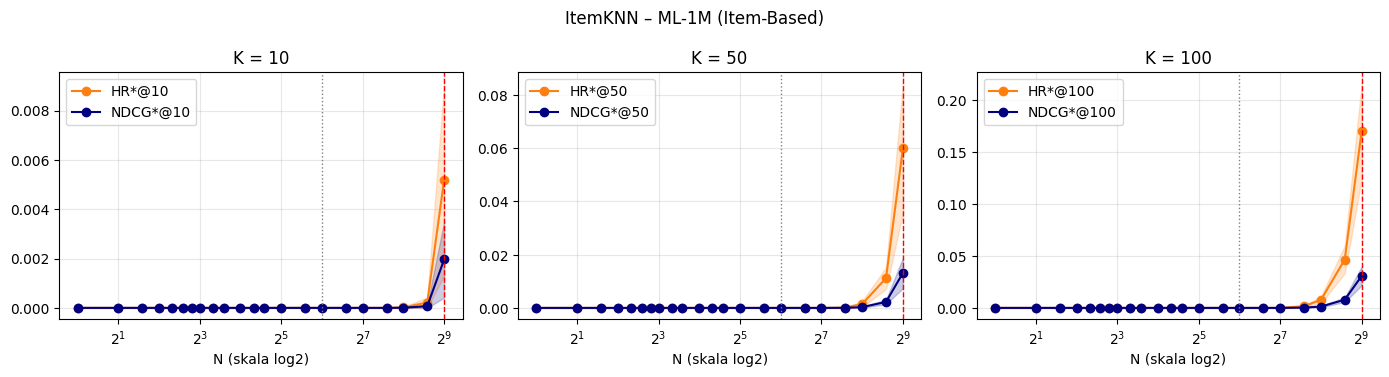

{10: 512, 50: 512, 100: 512}
Item dengan HR*@100 > 0 pada N terbesar yang diuji: 61 dari 64


In [9]:
if RUN_ITEM_BASED:
    fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
    thr_item = {}
    for ax, K in zip(axes, (10, 50, 100)):
        for m, col in ((f"HR*@{K}", "tab:orange"), (f"NDCG*@{K}", "navy")):
            ax.plot(ib.N, ib[m], "o-", color=col, label=m)
            ax.fill_between(ib.N, ib[m]-ib[m+"_ci"], ib[m]+ib[m+"_ci"], color=col, alpha=.2)
        thr_item[K] = cw.detect_threshold(ib.N, ib[f"NDCG*@{K}"])[0]
        if thr_item[K]: ax.axvline(thr_item[K], color="red", ls="--", lw=1)
        ax.axvline(64, color="gray", ls=":", lw=1)   # batas grid N paper
        ax.set_xscale("log", base=2); ax.set(title=f"K = {K}", xlabel="N (skala log2)"); ax.legend(); ax.grid(alpha=.3)
    plt.suptitle("ItemKNN – ML-1M (Item-Based)"); plt.tight_layout()
    plt.savefig("../results/item_based_ml1m.png", dpi=150); plt.show()
    print(thr_item)
    print("Item dengan HR*@100 > 0 pada N terbesar yang diuji:",
          int((ib_raw[ib_raw.N == ib_raw.N.max()]["HR*@100"] > 0).sum()), "dari", int((ib_raw.N == ib_raw.N.max()).sum()))

## 7. Ringkasan vs Table 2 paper

In [10]:
rows = [dict(setup="User-Based", model=m, metrik=k, hasil=v,
             paper={"ItemKNN": "4 +- 1.4", "EASE^R": "5 +- 1.1"}[m]) for m, d in thr_user.items() for k, v in d.items()]
if RUN_ITEM_BASED:
    rows += [dict(setup="Item-Based", model="ItemKNN", metrik=f"NDCG*@{K}", hasil=v, paper="9 +- 1.8") for K, v in thr_item.items()]
summary = pd.DataFrame(rows); summary.to_csv("../results/summary.csv", index=False); summary

,setup,model,metrik,hasil,paper
0,User-Based,ItemKNN,HR,4,4 +- 1.4
1,User-Based,ItemKNN,NDCG,4,4 +- 1.4
2,User-Based,EASE^R,HR,4,5 +- 1.1
3,User-Based,EASE^R,NDCG,5,5 +- 1.1
4,Item-Based,ItemKNN,NDCG*@10,512,9 +- 1.8
5,Item-Based,ItemKNN,NDCG*@50,512,9 +- 1.8
6,Item-Based,ItemKNN,NDCG*@100,512,9 +- 1.8
